# Chapter 7: Numbers vs Numbers

Companion notebook for *Master Exploratory Data Analysis: A Hands-On Beginner's Guide with Python, Statistics & A/B Testing*.

Run the cells from top to bottom (**Kernel → Restart Kernel and Run All Cells**). The data files are in the same folder as this notebook.

## 7.1 One Row per Customer

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

plt.style.use('book.mplstyle')

customers = pd.read_csv('customers.csv', parse_dates=['signup_date'])
orders = pd.read_csv('orders.csv', parse_dates=['order_date'])
cancellations = pd.read_csv('cancellations.csv',
                            parse_dates=['cancel_date'])
customers[['customer_id', 'signup_date', 'age', 'plan']].head()

,customer_id,signup_date,age,plan
0,1001,2024-01-01,45.0,Basic
1,1002,2024-01-01,30.0,Basic
2,1003,2024-01-01,40.0,Standard
3,1004,2024-01-02,39.0,Basic
4,1005,2024-01-02,28.0,Basic


### Tenure in months

In [2]:
customers = customers.merge(
    cancellations[['customer_id', 'cancel_date']],
    on='customer_id', how='left', validate='one_to_one')
data_end = pd.Timestamp('2025-12-31')
customers['end_date'] = customers['cancel_date'].fillna(data_end)
customers[['signup_date', 'cancel_date', 'end_date']].head(3)

,signup_date,cancel_date,end_date
0,2024-01-01,NaT,2025-12-31
1,2024-01-01,2024-01-08,2024-01-08
2,2024-01-01,2025-04-26,2025-04-26


In [3]:
days = (customers['end_date'] - customers['signup_date']).dt.days
customers['tenure_months'] = (days / 30.44).round(1)
customers['tenure_months'].describe().round(1)

count    4210.0
mean        5.3
std         5.2
min         0.0
25%         1.2
50%         3.4
75%         7.9
max        24.0
Name: tenure_months, dtype: float64

### Total spend and number of orders

In [4]:
spend = orders.groupby('customer_id')['amount'].sum()
order_count = orders.groupby('customer_id').size()
customers['total_spend'] = customers['customer_id'].map(spend)
customers['orders'] = customers['customer_id'].map(order_count)

per_customer = customers[['tenure_months', 'total_spend', 'orders',
                          'age']]
per_customer.describe().round(1)

,tenure_months,total_spend,orders,age
count,4210.0,4210.0,4210.0,4043.0
mean,5.3,184.1,6.8,38.0
std,5.2,227.1,6.3,10.8
min,0.0,8.0,1.0,18.0
25%,1.2,24.6,2.0,30.0
50%,3.4,95.4,5.0,38.0
75%,7.9,249.6,10.0,45.0
max,24.0,1527.2,32.0,76.0


## 7.2 Scatter Plots

### `sns.scatterplot()`

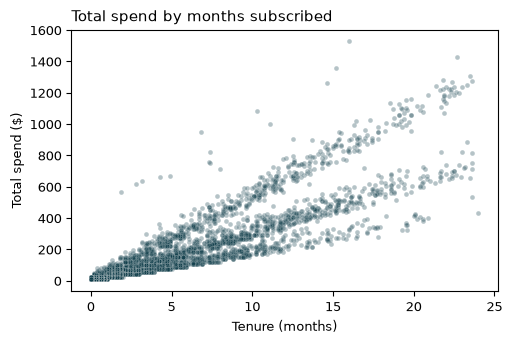

In [5]:
ax = sns.scatterplot(data=customers, x='tenure_months',
                     y='total_spend', alpha=0.3, s=12,
                     color='#0b3a47')
ax.set_title('Total spend by months subscribed')
ax.set_xlabel('Tenure (months)')
ax.set_ylabel('Total spend ($)')
plt.show()

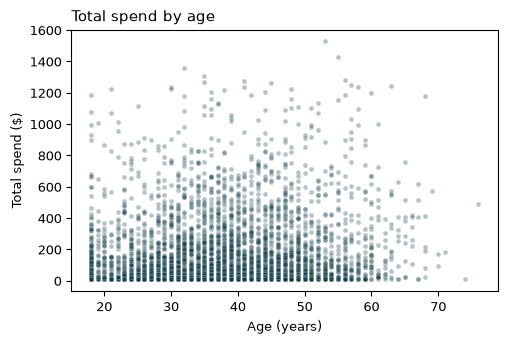

In [6]:
ax = sns.scatterplot(data=customers, x='age', y='total_spend',
                     alpha=0.3, s=12, color='#0b3a47')
ax.set_title('Total spend by age')
ax.set_xlabel('Age (years)')
ax.set_ylabel('Total spend ($)')
plt.show()

## 7.3 Pearson's r

### What different values look like

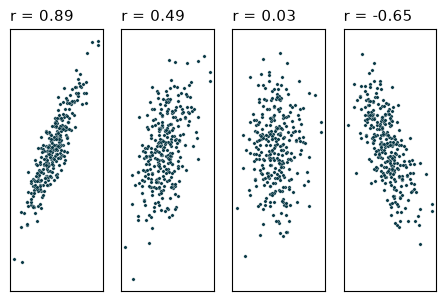

In [7]:
rng = np.random.default_rng(42)
x = rng.normal(size=300)
noise = rng.normal(size=300)

fig, axes = plt.subplots(1, 4, sharey=True)
for ax, target in zip(axes, [0.9, 0.5, 0.0, -0.7]):
    y = target * x + np.sqrt(1 - target**2) * noise
    r = pd.Series(x).corr(pd.Series(y))
    sns.scatterplot(x=x, y=y, s=6, color='#0b3a47', ax=ax)
    ax.set_title(f'r = {r:.2f}')
    ax.set_xticks([])
    ax.set_yticks([])
plt.show()

### `s.corr()`

In [8]:
tenure_spend = customers['tenure_months'].corr(
    customers['total_spend'])
age_spend = customers['age'].corr(customers['total_spend'])
print(f'Tenure vs spend: r = {tenure_spend:.2f}')
print(f'Age vs spend:    r = {age_spend:.2f}')

Tenure vs spend: r = 0.88
Age vs spend:    r = 0.10


### How r is worked out

In [9]:
z_tenure = stats.zscore(customers['tenure_months'])
z_spend = stats.zscore(customers['total_spend'])
print(f'Average of z-score products: {(z_tenure * z_spend).mean():.2f}')

Average of z-score products: 0.88


### `stats.pearsonr()`

In [10]:
tenure_result = stats.pearsonr(customers['tenure_months'],
                               customers['total_spend'])
print(f'r = {tenure_result.statistic:.2f}')

r = 0.88


In [11]:
age_result = stats.pearsonr(customers['age'],
                            customers['total_spend'])
print(f'r = {age_result.statistic}')

r = nan


In [12]:
with_age = customers.dropna(subset=['age'])
age_result = stats.pearsonr(with_age['age'], with_age['total_spend'])
print(f'r = {age_result.statistic:.2f}')

r = 0.10


## 7.4 Rank Correlation: Spearman and Kendall

### A curve that Pearson underrates

In [13]:
growth = pd.DataFrame({'week': [1, 2, 3, 4, 5, 6],
                       'bags': [1, 2, 4, 8, 16, 32]})
growth['week_rank'] = growth['week'].rank()
growth['bags_rank'] = growth['bags'].rank()
growth

,week,bags,week_rank,bags_rank
0,1,1,1.0,1.0
1,2,2,2.0,2.0
2,3,4,3.0,3.0
3,4,8,4.0,4.0
4,5,16,5.0,5.0
5,6,32,6.0,6.0


In [14]:
raw_r = growth['week'].corr(growth['bags'])
rank_r = growth['week_rank'].corr(growth['bags_rank'])
print(f'Pearson on the values: {raw_r:.2f}')
print(f'Pearson on the ranks:  {rank_r:.2f}')

Pearson on the values: 0.91
Pearson on the ranks:  1.00


### Orders and spend

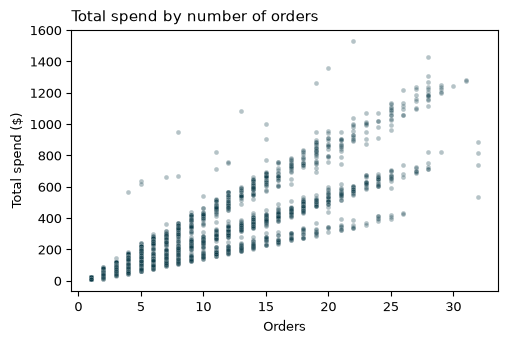

In [15]:
ax = sns.scatterplot(data=customers, x='orders', y='total_spend',
                     alpha=0.3, s=12, color='#0b3a47')
ax.set_title('Total spend by number of orders')
ax.set_xlabel('Orders')
ax.set_ylabel('Total spend ($)')
plt.show()

### `df.corr()` with `method=`

In [16]:
pair = customers[['orders', 'total_spend']]
pd.DataFrame({'pearson': pair.corr()['total_spend'],
              'spearman': pair.corr(method='spearman')['total_spend'],
              'kendall': pair.corr(method='kendall')['total_spend']}
             ).round(2)

,pearson,spearman,kendall
orders,0.9,0.96,0.85
total_spend,1.0,1.00,1.00


### `stats.spearmanr()`

In [17]:
orders_rho = stats.spearmanr(customers['orders'],
                             customers['total_spend'])
print(f'rho = {orders_rho.statistic:.2f}')

rho = 0.96


### `stats.kendalltau()`

In [18]:
orders_tau = stats.kendalltau(customers['orders'],
                              customers['total_spend'])
print(f'tau = {orders_tau.statistic:.2f}')

tau = 0.85


## 7.5 Outliers Move Pearson

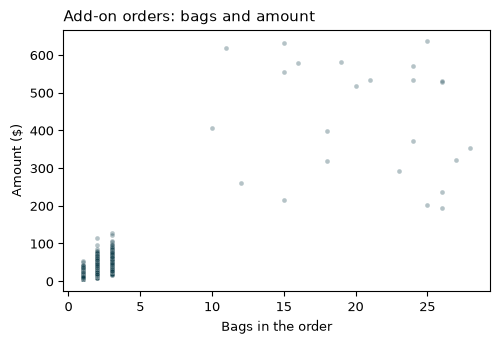

In [19]:
add_ons = orders[orders['order_type'] == 'Add-on']

ax = sns.scatterplot(data=add_ons, x='items', y='amount',
                     alpha=0.3, s=12, color='#0b3a47')
ax.set_title('Add-on orders: bags and amount')
ax.set_xlabel('Bags in the order')
ax.set_ylabel('Amount ($)')
plt.show()

In [20]:
regular = add_ons[add_ons['items'] < 10]
print(f'Gift orders: {(add_ons["items"] >= 10).sum()} '
      f'of {len(add_ons):,}')
for label, data in [('All add-ons', add_ons),
                    ('Without gifts', regular)]:
    r = data['items'].corr(data['amount'])
    rho = data['items'].corr(data['amount'], method='spearman')
    print(f'{label}: Pearson {r:.2f}, Spearman {rho:.2f}')

Gift orders: 24 of 4,520
All add-ons: Pearson 0.86, Spearman 0.75
Without gifts: Pearson 0.74, Spearman 0.74


## 7.6 Strength Isn't Slope

### `sns.regplot()`

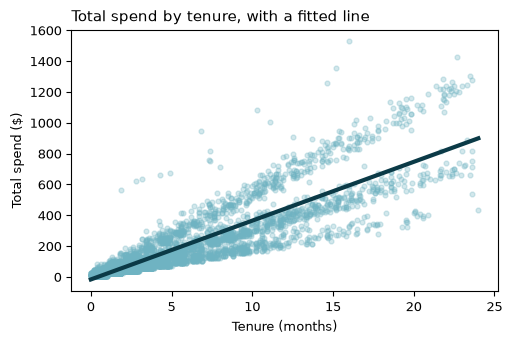

In [21]:
ax = sns.regplot(data=customers, x='tenure_months', y='total_spend',
                 ci=None, color='#6fb3c2',
                 scatter_kws={'alpha': 0.3, 's': 12},
                 line_kws={'color': '#0b3a47'})
ax.set_title('Total spend by tenure, with a fitted line')
ax.set_xlabel('Tenure (months)')
ax.set_ylabel('Total spend ($)')
plt.show()

### Same r, different slopes

In [22]:
for plan in ['Basic', 'Standard', 'Premium']:
    group = customers[customers['plan'] == plan]
    r = group['tenure_months'].corr(group['total_spend'])
    slope = np.polyfit(group['tenure_months'],
                       group['total_spend'], 1)[0]
    print(f'{plan:<9} r = {r:.2f}   slope = ${slope:.0f} per month')

Basic     r = 0.89   slope = $20 per month
Standard  r = 0.98   slope = $32 per month
Premium   r = 0.98   slope = $55 per month


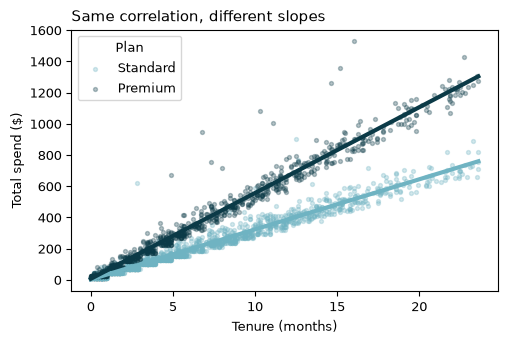

In [23]:
fig, ax = plt.subplots()
for plan, color in [('Standard', '#6fb3c2'), ('Premium', '#0b3a47')]:
    sns.regplot(data=customers[customers['plan'] == plan],
                x='tenure_months', y='total_spend', ci=None,
                color=color, label=plan,
                scatter_kws={'alpha': 0.3, 's': 8}, ax=ax)
ax.legend(title='Plan')
ax.set_title('Same correlation, different slopes')
ax.set_xlabel('Tenure (months)')
ax.set_ylabel('Total spend ($)')
plt.show()

## 7.7 Many Pairs at Once with a Heatmap

In [24]:
orders['late'] = orders['delivery_days'] > 5
by_customer = orders.groupby('customer_id')
customers['late_boxes'] = customers['customer_id'].map(
    by_customer['late'].sum())
customers['avg_delivery'] = customers['customer_id'].map(
    by_customer['delivery_days'].mean())

short_names = {'tenure_months': 'tenure', 'total_spend': 'spend',
               'late_boxes': 'late', 'avg_delivery': 'delivery'}
columns = ['tenure_months', 'orders', 'total_spend', 'late_boxes',
           'avg_delivery', 'age']
corr_table = customers[columns].rename(columns=short_names).corr()
corr_table.round(2)

,tenure,orders,spend,late,delivery,age
tenure,1.00,0.99,0.88,0.50,-0.11,0.09
orders,0.99,1.00,0.90,0.51,-0.10,0.12
spend,0.88,0.90,1.00,0.47,-0.08,0.10
late,0.50,0.51,0.47,1.00,0.38,0.08
delivery,-0.11,-0.10,-0.08,0.38,1.00,0.01
age,0.09,0.12,0.10,0.08,0.01,1.00


### `sns.heatmap()`

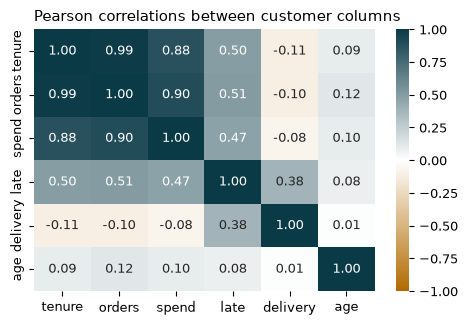

In [25]:
book_diverging = sns.blend_palette(['#b26a00', 'white', '#0b3a47'],
                                   as_cmap=True)
ax = sns.heatmap(corr_table, annot=True, fmt='.2f', vmin=-1, vmax=1,
                 cmap=book_diverging)
ax.set_title('Pearson correlations between customer columns')
plt.show()

## 7.8 Correlation Is Not Causation

### Finding the lurking variable

In [26]:
customers['late_share'] = customers['customer_id'].map(
    by_customer['late'].mean())
check = customers[['tenure_months', 'total_spend', 'late_boxes',
                   'late_share']].corr()
check.loc[['late_boxes', 'late_share'],
          ['tenure_months', 'total_spend']].round(2)

,tenure_months,total_spend
late_boxes,0.5,0.47
late_share,-0.1,-0.07
